# Chapter 5 — predicting multi-skip collapse from single skips

**Question:** if we know the accuracy damage of skipping block *a* alone, and block *b* alone, can we predict the damage of skipping both — as one contiguous 2-block span, or as two disjoint single-block skips?

Three predictors of multi-skip damage, all built from single-block drops:

- **naive** — sum of single-block drops, no fitting: `predicted = drop(a) + drop(b)`
- **cka** — naive sum + a learned CKA-similarity correction term, fit per (model, dataset)
- **ang_dist** — naive sum + a learned angular-distance correction term, fit per (model, dataset)

Each is scored by **Pearson r** (does it track the *magnitude* of damage?) and **Spearman rank r** (does it correctly *rank* skips from safest to most damaging?), against the actual measured multi-skip damage. Checked separately for **continuous** (contiguous 2-block spans) and **disjoint** (two separate single-block skips) shapes, then we stratify the disjoint case by the gap between the two skips.

Every number below is computed in this notebook from `distance_analysis.csv` (the raw accuracy sweeps) and the per-(model, dataset) CKA / angular-distance matrices in `npy_matrices/` — nothing is loaded pre-aggregated. See `NOTES.md` for the narrative write-up.

In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

NPY_DIR = Path("npy_matrices")

df = pd.read_csv("distance_analysis.csv")
df["skip_count"] = df["skip_count"].astype(int)
df["spans"] = df["approx_layer_str"].map(ast.literal_eval)
df.head()

,model,dataset,approx_layer_str,translator_linear,accuracy_mean_linear,accuracy_std_linear,skip_distance,skip_count,first_skip,translator_identity,accuracy_mean_identity,accuracy_std_identity,spans
0,facebook/deit-base-patch16-224,pneumoniamnist,[],linear,0.819,0.017,0,0,-1,identity,0.819,0.017,[]
1,facebook/deit-base-patch16-224,imagenet-1k,[],linear,0.776,0.002,0,0,-1,identity,0.776,0.002,[]
2,facebook/deit-base-patch16-224,cifar100,[],linear,0.755,0.002,0,0,-1,identity,0.755,0.002,[]
3,facebook/deit-base-patch16-224,dermamnist,[],linear,0.740,0.002,0,0,-1,identity,0.740,0.002,[]
4,facebook/deit-small-patch16-224,pneumoniamnist,[],linear,0.786,0.009,0,0,-1,identity,0.786,0.009,[]


## Helper functions

`dropped_blocks` turns a span list into the concrete block indices it removes. `ols_with_intercept` / `loo_cv_predictions` fit a plain linear regression and produce leave-one-out cross-validated predictions (so a correction term's score reflects genuine out-of-sample performance, not overfitting to its own fit). `pearson`/`spearman` wrap `scipy.stats` and return `nan` on too-small or degenerate inputs instead of raising.

In [2]:
def dropped_blocks(spans):
    blocks = []
    for start, end in spans:
        blocks.extend(range(start + 1, end + 1))
    return blocks


def ols_with_intercept(X, y):
    design = np.column_stack([np.ones(len(X)), X])
    coefs, *_ = np.linalg.lstsq(design, y, rcond=None)
    return coefs


def predict(design_row, coefs):
    return coefs[0] + np.dot(design_row, coefs[1:])


def loo_cv_predictions(X, y):
    n = len(y)
    preds = np.empty(n)
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        coefs = ols_with_intercept(X[mask], y[mask])
        preds[i] = predict(X[i], coefs)
    return preds


def safe_corr(fn, a, b):
    a, b = np.asarray(a), np.asarray(b)
    if len(a) < 3 or np.std(a) == 0 or np.std(b) == 0:
        return float("nan")
    return fn(a, b)[0]


def pearson(a, b):
    return safe_corr(pearsonr, a, b)


def spearman(a, b):
    return safe_corr(spearmanr, a, b)


def single_block_drops(group):
    """baseline - accuracy for every skip_count==1 row, keyed by the dropped block index."""
    baseline = group[group["skip_count"] == 0]["accuracy_mean_linear"].iloc[0]
    drops = {}
    for _, row in group[group["skip_count"] == 1].iterrows():
        blocks = dropped_blocks(row["spans"])
        if len(blocks) == 1:
            drops[blocks[0]] = baseline - row["accuracy_mean_linear"]
    return baseline, drops


def load_matrix(model, dataset, metric):
    stem = model.replace("/", "_")
    path = NPY_DIR / f"{stem}_{dataset}_{metric}.npy"
    return np.load(path) if path.exists() else None

## 1. Continuous — contiguous 2-block spans, e.g. `[(0, 2)]`

Restricted to cifar100 and imagenet-1k (natural-image datasets). For every (model, dataset) with a contiguous 2-block sweep:

- **naive**: `predicted_delta = drop(a) + drop(a+1)` (no fitting)
- **cka / ang_dist**: fit `delta_acc ~ intercept + coef_metric * metric(a, a+1) + coef_sum * block_drop_sum` by OLS, score with **leave-one-out** predictions so the correction term can't just memorise its own training spans

In [3]:
continuous_rows = []
continuous_datasets = ["cifar100", "imagenet-1k"]

for (model, dataset), group in df[df["dataset"].isin(continuous_datasets)].groupby(["model", "dataset"]):
    baseline, single_drop = single_block_drops(group)
    two = group[(group["skip_count"] == 2) & (group["skip_distance"] == 1)].copy()
    if two.empty:
        continue
    two["delta_acc"] = baseline - two["accuracy_mean_linear"]

    naive_pred, actual, cka_vals, ang_vals, sum_vals = [], [], [], [], []
    cka_matrix = load_matrix(model, dataset, "cka")
    ang_matrix = load_matrix(model, dataset, "angdist")
    for _, row in two.iterrows():
        (start, end), = row["spans"]
        blocks = dropped_blocks(row["spans"])
        drops = [single_drop.get(b) for b in blocks]
        if any(d is None for d in drops):
            continue
        naive_pred.append(sum(drops))
        actual.append(row["delta_acc"])
        sum_vals.append(sum(drops))
        cka_vals.append(cka_matrix[start + 1, end + 1] if cka_matrix is not None else np.nan)
        ang_vals.append(ang_matrix[start + 1, end + 1] if ang_matrix is not None else np.nan)

    if len(actual) < 5:
        continue
    actual = np.array(actual)
    naive_pred = np.array(naive_pred)
    sum_vals = np.array(sum_vals)

    continuous_rows.append({
        "model": model, "dataset": dataset, "predictor": "naive", "n": len(actual),
        "pearson_r": pearson(actual, naive_pred), "spearman_r": spearman(actual, naive_pred),
    })

    for label, metric_vals in [("cka", cka_vals), ("angdist", ang_vals)]:
        metric_vals = np.array(metric_vals)
        if np.isnan(metric_vals).any():
            continue
        X = np.column_stack([metric_vals, sum_vals])
        loo_pred = loo_cv_predictions(X, actual)
        continuous_rows.append({
            "model": model, "dataset": dataset, "predictor": label, "n": len(actual),
            "pearson_r": pearson(actual, loo_pred), "spearman_r": spearman(actual, loo_pred),
        })

continuous = pd.DataFrame(continuous_rows)
continuous.head()

,model,dataset,predictor,n,pearson_r,spearman_r
0,facebook/deit-base-patch16-224,cifar100,naive,10,0.966,0.952
1,facebook/deit-base-patch16-224,cifar100,cka,10,0.949,0.891
2,facebook/deit-base-patch16-224,cifar100,angdist,10,0.949,0.891
3,facebook/deit-base-patch16-224,imagenet-1k,naive,10,0.989,0.964
4,facebook/deit-base-patch16-224,imagenet-1k,cka,10,0.976,0.952


In [4]:
continuous_summary = continuous.groupby("predictor")[["pearson_r", "spearman_r"]].median().loc[["naive", "cka", "angdist"]]
print("Median across all (model, dataset) combos — continuous:")
continuous_summary

Median across all (model, dataset) combos — continuous:


,pearson_r,spearman_r
predictor,,
naive,0.894,0.902
cka,0.734,0.864
angdist,0.751,0.721


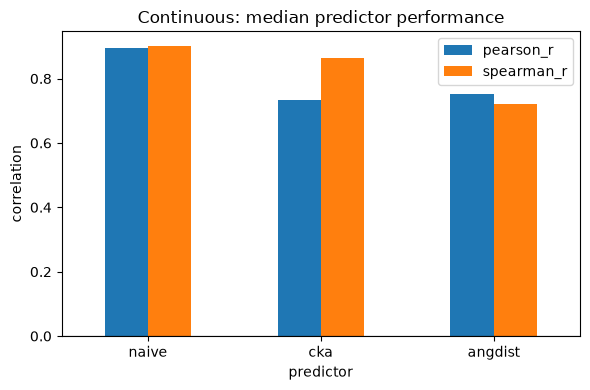

In [5]:
ax = continuous_summary.plot(kind="bar", figsize=(6, 4), rot=0)
ax.set_title("Continuous: median predictor performance")
ax.set_ylabel("correlation")
ax.set_xlabel("predictor")
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

Restricted to cifar100/imagenet-1k, naive summation is still the strongest median predictor (pearson 0.89, spearman 0.90) — the cka/ang_dist correction terms (pearson ~0.73–0.75) don't beat it on median, though the gap is narrower than it was across all 5 datasets, since the noisy chest-x-ray/derm/pneumonia combos that made the correction go strongly negative for dinov2-base/vit-base are excluded here. See the per-combo breakdown below for which of the remaining natural-image combos the correction actually helps on.

In [6]:
continuous.pivot_table(index=["model", "dataset"], columns="predictor", values="pearson_r").round(3)

predictor                                    angdist    cka  naive
model                           dataset                           
facebook/deit-base-patch16-224  cifar100       0.949  0.949  0.966
                                imagenet-1k    0.973  0.976  0.989
facebook/deit-small-patch16-224 cifar100       0.963  0.958  0.990
                                imagenet-1k    0.941  0.912  0.969
facebook/dinov2-base            cifar100       0.065  0.366  0.762
                                imagenet-1k    0.498  0.618  0.873
google/vit-base-patch16-224     cifar100       0.973  0.850  0.937
                                imagenet-1k    0.530  0.467  0.687
google/vit-large-patch16-224    cifar100       0.675  0.442  0.858
                                imagenet-1k    0.695  0.442  0.873
microsoft/rad-dino              cifar100       0.806  0.890  0.915
                                imagenet-1k    0.029 -0.175  0.442

## 2. Disjoint — two separate single-block skips, e.g. `[(0, 1), (2, 3)]`

Restricted to imagenet-1k (the only dataset with a disjoint sweep at all). Same three predictors, same two correlations, across the 3 models that have it: deit-small, dinov2-base, vit-large. The disjoint regression keeps the two similarity values **separate** (`metric_1`, `metric_2`) rather than summing them, since the two skips are distinct bridges and summing would throw away which one is more responsible for the damage.

In [7]:
disjoint_rows = []
disjoint_span_records = []  # kept for the gap-stratification section below
disjoint_dataset = "imagenet-1k"

for (model, dataset), group in df[df["dataset"] == disjoint_dataset].groupby(["model", "dataset"]):
    baseline, single_drop = single_block_drops(group)
    two = group[(group["skip_count"] == 2) & (group["skip_distance"] > 1)].copy()
    if two.empty:
        continue
    two["delta_acc"] = baseline - two["accuracy_mean_linear"]

    naive_pred, actual, cka1, cka2, ang1, ang2, sum_vals, gaps = [], [], [], [], [], [], [], []
    cka_matrix = load_matrix(model, dataset, "cka")
    ang_matrix = load_matrix(model, dataset, "angdist")
    for _, row in two.iterrows():
        (s1, e1), (s2, e2) = sorted(row["spans"])
        b1, b2 = dropped_blocks([(s1, e1)])[0], dropped_blocks([(s2, e2)])[0]
        d1, d2 = single_drop.get(b1), single_drop.get(b2)
        if d1 is None or d2 is None:
            continue
        naive_pred.append(d1 + d2)
        actual.append(row["delta_acc"])
        sum_vals.append(d1 + d2)
        gaps.append(row["skip_distance"])
        cka1.append(cka_matrix[s1 + 1, e1 + 1] if cka_matrix is not None else np.nan)
        cka2.append(cka_matrix[s2 + 1, e2 + 1] if cka_matrix is not None else np.nan)
        ang1.append(ang_matrix[s1 + 1, e1 + 1] if ang_matrix is not None else np.nan)
        ang2.append(ang_matrix[s2 + 1, e2 + 1] if ang_matrix is not None else np.nan)

    if len(actual) < 5:
        continue
    actual = np.array(actual)
    naive_pred = np.array(naive_pred)
    sum_vals = np.array(sum_vals)

    for gap, a, p in zip(gaps, actual, naive_pred):
        disjoint_span_records.append({"model": model, "dataset": dataset, "gap": gap, "actual": a, "naive_pred": p})

    disjoint_rows.append({
        "model": model, "dataset": dataset, "predictor": "naive", "n": len(actual),
        "pearson_r": pearson(actual, naive_pred), "spearman_r": spearman(actual, naive_pred),
    })

    for label, v1, v2 in [("cka", cka1, cka2), ("angdist", ang1, ang2)]:
        v1, v2 = np.array(v1), np.array(v2)
        if np.isnan(v1).any() or np.isnan(v2).any():
            continue
        X = np.column_stack([v1, v2, sum_vals])
        loo_pred = loo_cv_predictions(X, actual)
        disjoint_rows.append({
            "model": model, "dataset": dataset, "predictor": label, "n": len(actual),
            "pearson_r": pearson(actual, loo_pred), "spearman_r": spearman(actual, loo_pred),
        })

disjoint = pd.DataFrame(disjoint_rows)
disjoint_span_df = pd.DataFrame(disjoint_span_records)
disjoint

,model,dataset,predictor,n,pearson_r,spearman_r
0,facebook/deit-small-patch16-224,imagenet-1k,naive,45,0.969,0.944
1,facebook/deit-small-patch16-224,imagenet-1k,cka,45,0.975,0.950
2,facebook/deit-small-patch16-224,imagenet-1k,angdist,45,0.977,0.952
3,facebook/dinov2-base,imagenet-1k,naive,45,0.989,0.988
4,facebook/dinov2-base,imagenet-1k,cka,45,0.987,0.984
5,facebook/dinov2-base,imagenet-1k,angdist,45,0.987,0.983
6,google/vit-large-patch16-224,imagenet-1k,naive,186,0.999,0.901
7,google/vit-large-patch16-224,imagenet-1k,cka,186,0.999,0.886
8,google/vit-large-patch16-224,imagenet-1k,angdist,186,0.999,0.922


In [8]:
disjoint_summary = disjoint.groupby("predictor")[["pearson_r", "spearman_r"]].median().loc[["naive", "cka", "angdist"]]
print("Median across the 3 disjoint combos:")
disjoint_summary

Median across the 3 disjoint combos:


,pearson_r,spearman_r
predictor,,
naive,0.989,0.944
cka,0.987,0.950
angdist,0.987,0.952


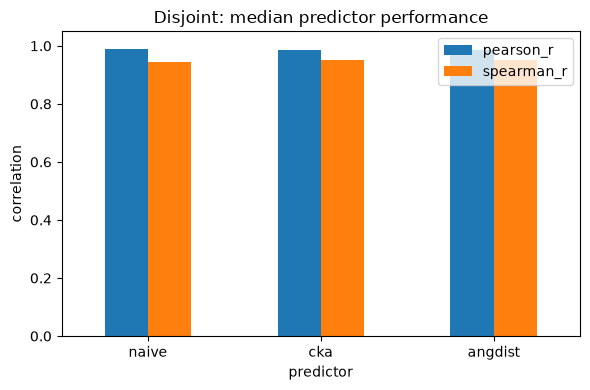

In [9]:
ax = disjoint_summary.plot(kind="bar", figsize=(6, 4), rot=0, ylim=(0, 1.05))
ax.set_title("Disjoint: median predictor performance")
ax.set_ylabel("correlation")
ax.set_xlabel("predictor")
plt.tight_layout()
plt.show()

All three predictors are essentially equivalent and all strong (~0.94–0.99). Disjoint damage is close to additive on its own; the correction terms neither help nor hurt meaningfully because there's almost no residual signal left to capture.

In [10]:
disjoint.pivot_table(index=["model", "dataset"], columns="predictor", values=["pearson_r", "spearman_r"]).round(3)

pearson_r             spearman_r  \
predictor                                     angdist   cka naive    angdist   
model                           dataset                                        
facebook/deit-small-patch16-224 imagenet-1k     0.977 0.975 0.969      0.952   
facebook/dinov2-base            imagenet-1k     0.987 0.987 0.989      0.983   
google/vit-large-patch16-224    imagenet-1k     0.999 0.999 0.999      0.922   

                                                         
predictor                                     cka naive  
model                           dataset                  
facebook/deit-small-patch16-224 imagenet-1k 0.950 0.944  
facebook/dinov2-base            imagenet-1k 0.984 0.988  
google/vit-large-patch16-224    imagenet-1k 0.886 0.901

## 3. Stratify the disjoint case by distance between the two skips

Split each model's disjoint spans into three equal-sized bins by gap (near / mid / far — a simple tercile split by rank), then re-check the **naive** additive predictor's Pearson r and R² within each bin.

In [11]:
def r_squared(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    ss_res = ((actual - predicted) ** 2).sum()
    ss_tot = ((actual - actual.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot if ss_tot else float("nan")


gap_rows = []
gap_labels = ["near", "mid", "far"]
for model, g in disjoint_span_df.groupby("model"):
    g = g.sort_values("gap").reset_index(drop=True)
    bins = np.array_split(g, 3)
    for label, b in zip(gap_labels, bins):
        gap_rows.append({
            "model": model, "dataset": g["dataset"].iloc[0] if "dataset" in g else "imagenet-1k",
            "gap_bin": label, "n": len(b), "gap_min": b["gap"].min(), "gap_max": b["gap"].max(),
            "r2": r_squared(b["actual"], b["naive_pred"]), "pearson": pearson(b["actual"], b["naive_pred"]),
        })

gap_stratified = pd.DataFrame(gap_rows)
gap_stratified["gap_bin"] = pd.Categorical(gap_stratified["gap_bin"], categories=gap_labels, ordered=True)
gap_stratified.sort_values(["model", "gap_bin"]).reset_index(drop=True)

/Users/mabelwylie/.pyenv/versions/3.12.0/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


,model,dataset,gap_bin,n,gap_min,gap_max,r2,pearson
0,facebook/deit-small-patch16-224,imagenet-1k,near,15,2,3,0.556,0.966
1,facebook/deit-small-patch16-224,imagenet-1k,mid,15,3,5,0.858,0.972
2,facebook/deit-small-patch16-224,imagenet-1k,far,15,6,10,0.992,0.998
3,facebook/dinov2-base,imagenet-1k,near,15,2,3,0.923,0.988
4,facebook/dinov2-base,imagenet-1k,mid,15,3,5,0.925,0.995
5,facebook/dinov2-base,imagenet-1k,far,15,6,10,0.970,0.996
6,google/vit-large-patch16-224,imagenet-1k,near,62,2,5,0.996,0.998
7,google/vit-large-patch16-224,imagenet-1k,mid,62,5,8,0.998,1.000
8,google/vit-large-patch16-224,imagenet-1k,far,62,8,13,1.000,1.000


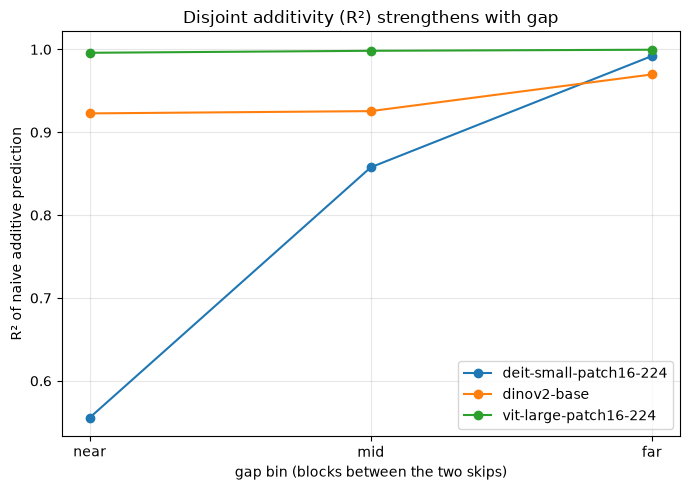

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
for model, g in gap_stratified.groupby("model"):
    g = g.sort_values("gap_bin")
    ax.plot(g["gap_bin"].astype(str), g["r2"], marker="o", label=model.split("/")[-1])
ax.set_title("Disjoint additivity (R\u00b2) strengthens with gap")
ax.set_xlabel("gap bin (blocks between the two skips)")
ax.set_ylabel("R\u00b2 of naive additive prediction")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Additivity gets more exact as the gap widens for all three models — the farther apart the two skipped blocks are, the less they interact, and the closer naive summation gets to exact. This is the mechanism behind section 2's result: disjoint pairs are already spatially separated, so they start close to additive.

## 4. Illustrative example — vit-large / imagenet-1k

Raw accuracy curves behind the numbers above: single-block skips, contiguous 2-block skips, and disjoint skips with exactly one untouched block between them.

In [13]:
model = "google/vit-large-patch16-224"
dataset = "imagenet-1k"
md_df = df[(df["model"] == model) & (df["dataset"] == dataset)].copy()
baseline = md_df[md_df["approx_layer_str"] == "[]"]["accuracy_mean_linear"].iloc[0]

best_val = md_df["accuracy_mean_linear"].max() + 0.02
worst_val = md_df["accuracy_mean_linear"].min() - 0.02

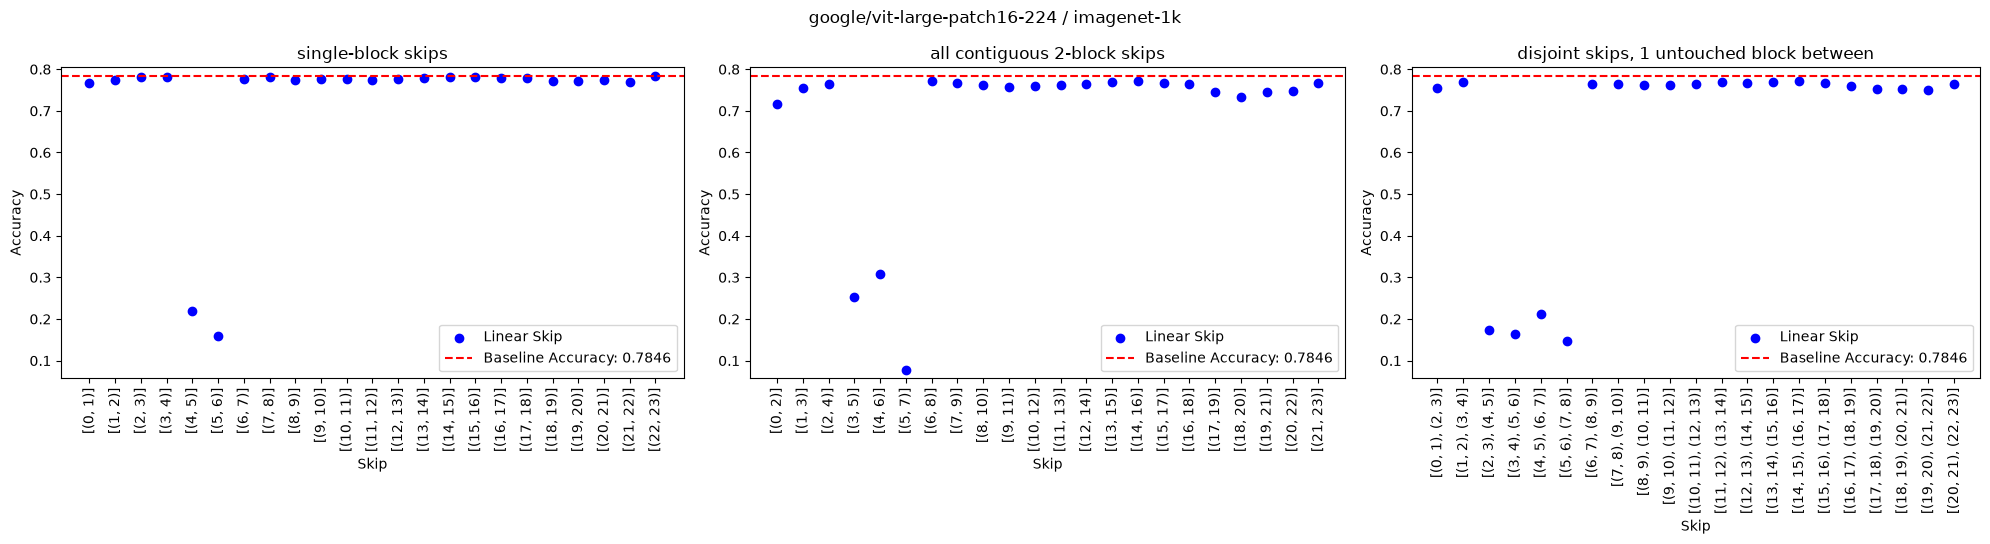

In [14]:
single = md_df[md_df["skip_count"] == 1].sort_values(by="first_skip")
contiguous_two = md_df[(md_df["skip_count"] == 2) & (md_df["skip_distance"] == 1)].sort_values(by="first_skip")
gapped = md_df[(md_df["skip_count"] == 2) & (md_df["skip_distance"] == 2)].sort_values(by="first_skip")

panels = [
    (single, "single-block skips"),
    (contiguous_two, "all contiguous 2-block skips"),
    (gapped, "disjoint skips, 1 untouched block between"),
]
width_ratios = [len(data) for data, _ in panels]

fig, axes = plt.subplots(
    1, 3, figsize=(20, 5.5), width_ratios=width_ratios,
)
fig.suptitle(f"{model} / {dataset}")

for ax, (data, subtitle) in zip(axes, panels):
    ax.scatter(data["approx_layer_str"], data["accuracy_mean_linear"], color="blue", label="Linear Skip")
    ax.axhline(y=baseline, color="red", linestyle="--", label=f"Baseline Accuracy: {baseline:.4f}")
    ax.set_title(subtitle)
    ax.set_xlabel("Skip")
    ax.set_ylabel("Accuracy")
    ax.tick_params(axis="x", rotation=90)
    ax.set_ylim(worst_val, best_val)
    ax.legend()

plt.tight_layout()
plt.show()

## Takeaways

1. **Contiguous spans (cifar100, imagenet-1k)**: naive summation is still the more robust predictor on median; a learned cka/ang_dist correction term helps for some backbones but not universally — see the per-combo table.
2. **Disjoint pairs (imagenet-1k only, deit-small/dinov2-base/vit-large)**: naive summation already ranks and predicts skips well; cka and ang_dist correction terms are statistically indistinguishable from it.
3. **Stratifying disjoint pairs by gap** shows why disjoint is closer to additive than contiguous in the first place — additivity strengthens monotonically with distance, i.e. interaction between skipped blocks decays with separation.